In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')
rng = np.random.default_rng(42)

Task 1, scatter jointplot of Flipkart rating vs price from a CSV

   rating   price
0     4.2  1395.0
1     3.5  1613.0
2     4.4  1356.0
3     4.5  1608.0
4     3.0   150.0


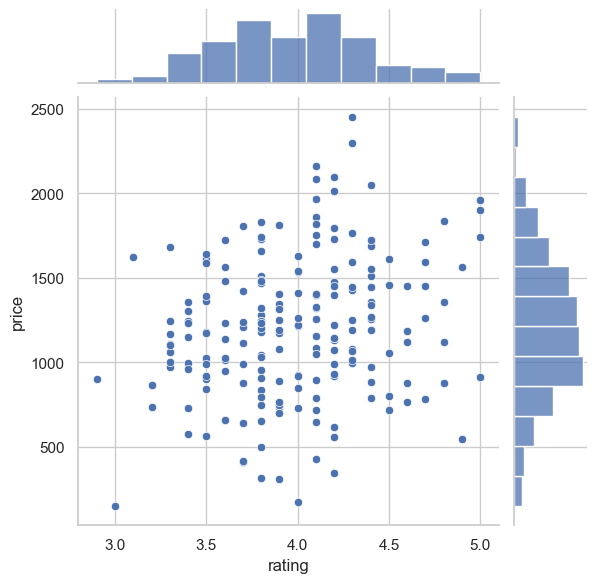

In [2]:
# Create a sample CSV first (skip if you have your own file)
n = 200
rating = rng.normal(4.0, 0.5, n).clip(1, 5).round(1)
price = (rng.normal(1200, 400, n) + (rating - 4) * 300).clip(150, None).round(0)
pd.DataFrame({'rating': rating, 'price': price}).to_csv('flipkart_ratings_prices.csv', index=False)

flipkart = pd.read_csv('flipkart_ratings_prices.csv')
print(flipkart.head())

sns.jointplot(data=flipkart, x='rating', y='price', kind='scatter')
plt.show()

Task 2, hexbin of Swiggy delivery time vs order value

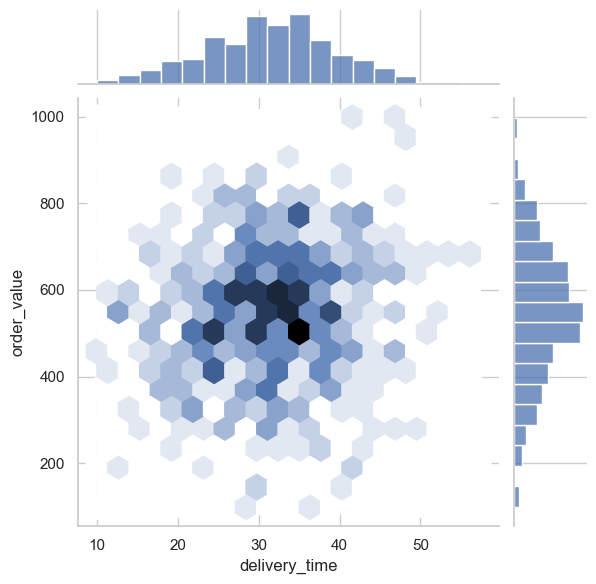

In [3]:
m = 500
delivery_time = rng.normal(32, 8, m).clip(10, None)
order_value = (rng.normal(450, 150, m) + delivery_time * 3).clip(100, None)
swiggy = pd.DataFrame({'delivery_time': delivery_time.round(1), 'order_value': order_value.round(0)})

sns.jointplot(x='delivery_time', y='order_value', data=swiggy, kind='hex')
plt.show()

Task 3, KDE of Instagram likes vs comments

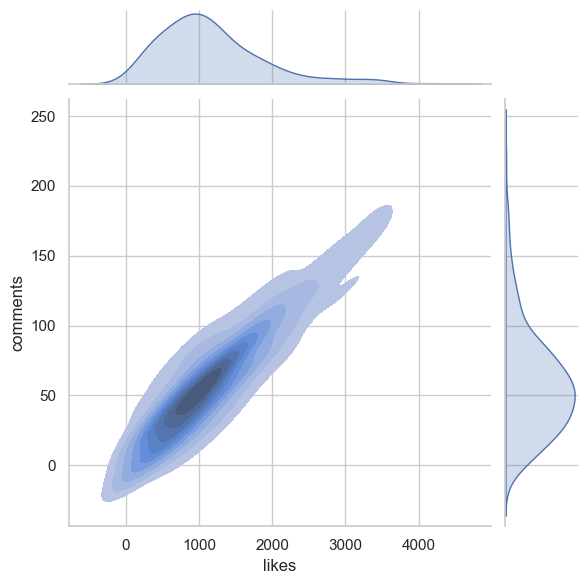

In [4]:
k = 300
likes = rng.gamma(3, 400, k)
comments = (likes * 0.05 + rng.normal(0, 15, k)).clip(0, None)
insta = pd.DataFrame({'likes': likes.round(0), 'comments': comments.round(0)})

sns.jointplot(data=insta, x='likes', y='comments', kind='kde', fill=True)
plt.show()

Task 4, all three kinds on the same Zomato data

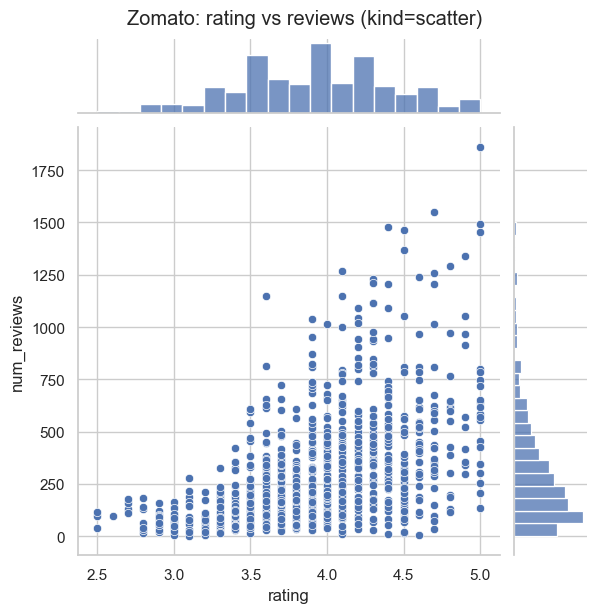

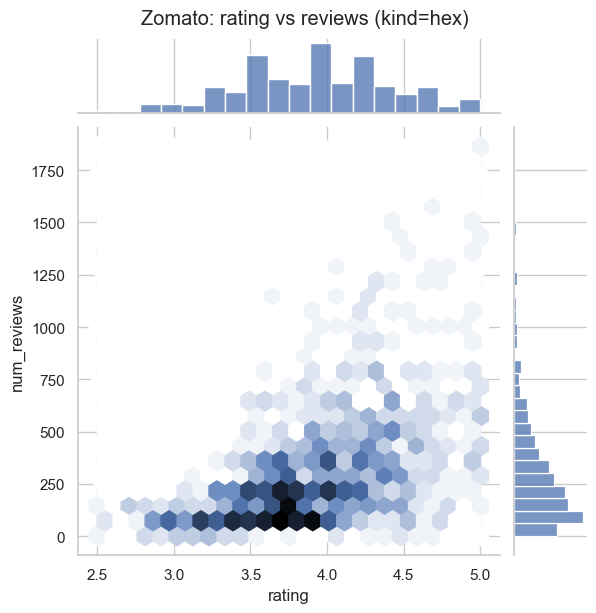

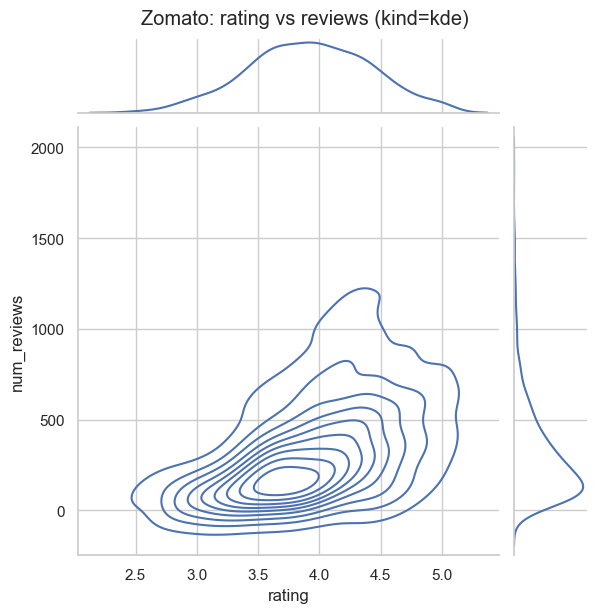

In [5]:
z = 1000
z_rating = rng.normal(3.9, 0.5, z).clip(1, 5)
z_reviews = rng.gamma(2, 150, z) * (1 + (z_rating - 3.9)).clip(0.3, None)
zomato = pd.DataFrame({'rating': z_rating.round(1), 'num_reviews': z_reviews.round(0)})

for kind in ['scatter', 'hex', 'kde']:
    g = sns.jointplot(data=zomato, x='rating', y='num_reviews', kind=kind)
    g.figure.suptitle(f'Zomato: rating vs reviews (kind={kind})', y=1.02)
    plt.show()